# **Slimme Supermarktweegschaal (Fruits-360)**
## **Context & Probleemstelling**
In moderne supermarkten (zoals Delhaize of Colruyt) zijn groente- en fruitweegschalen uitgerust met een ingebouwde camera. Wanneer een klant een product op de weegschaal legt, classificeert het systeem het product en toont een compact menu met suggesties (de Top-3 waarschijnlijkste opties).

In dit labo bouwen we een traditionele machine learning pipeline om dit gedrag te reproduceren op basis van de bekende Fruits-360 dataset:

## **Stap 1:** Libraries
We installeren en importeren alle benodigde bibliotheken voor beeldverwerking, modeltraining en visualisatie.

In [3]:
# Celinvoer: Installatie (indien nodig)
#!pip install -q kagglehub scikit-image xgboost scikit-learn seaborn matplotlib tqdm
import kagglehub
import os
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

import kagglehub
from skimage.io import imread
from skimage.transform import resize
from skimage.color import rgb2gray, rgb2hsv
from skimage.feature import hog

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, top_k_accuracy_score, classification_report, confusion_matrix

print("Alle imports succesvol geladen.")

c:\Users\chayb\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Alle imports succesvol geladen.


## **Stap 2:** Dataset Downloaden & Doelklassen Selecteren
Fruits-360 bevat meer dan 100 subvariëteiten. Om trainingstijd te beperken, selecteren we 10 typische supermarktproducten met een mix van duidelijke kleurverschillen en vormverschillen.

In [4]:
print("Bezig met downloaden van de compacte fruitdataset via kagglehub...")
dataset_root = kagglehub.dataset_download("souro12/ccxzvv")
root_path = Path(dataset_root)

# Zoek automatisch de map waar de fruitklassen in staan
target_dir = root_path
while True:
    subdirs = [d for d in target_dir.iterdir() if d.is_dir() and not d.name.startswith('.')]
    if len(subdirs) == 1:
        target_dir = subdirs[0]
    else:
        break

data_dir = target_dir
geselecteerde_klassen = sorted([d.name for d in data_dir.iterdir() if d.is_dir() and not d.name.startswith('.')])

print(f"\nData map ingesteld op: {data_dir}")
print(f"Aantal klassen gevonden ({len(geselecteerde_klassen)}):")
for k in geselecteerde_klassen:
    aantal = len(list((data_dir / k).glob("*.*")))
    print(f" - {k:<20} ({aantal} foto's)")

Bezig met downloaden van de compacte fruitdataset via kagglehub...

Data map ingesteld op: C:\Users\chayb\.cache\kagglehub\datasets\souro12\ccxzvv\versions\1\Fruits_1\Training
Aantal klassen gevonden (6):
 - Pineapple            (369 foto's)
 - Pineapple Mini       (450 foto's)
 - Raspberry            (420 foto's)
 - Redcurrant           (492 foto's)
 - Strawberry           (450 foto's)
 - Strawberry Wedge     (496 foto's)


## **Stap 3:** Preprocessing & Feature Engineering
Waarom volstaat HOG of kleur alleen niet op een weegschaal?

* HOG (Vorm & Textuur): Converteert naar grijswaarden en analyseert gradiënten. HOG herkent het verschil tussen een banaan en een sinaasappel, maar faalt bij Lemon (citroen) versus Lime (limoen) omdat beide dezelfde vorm hebben.

* HSV (Kleur): In tegenstelling tot RGB scheidt de HSV-kleurruimte de werkelijke tint (Hue) van de verzadiging (Saturation) en helderheid/schaduw (Value). Dit maakt kleurherkenning veel robuuster tegen wisselende belichting in de winkel.

Onderstaande cel laadt één testbeeld en toont de berekende features visueel

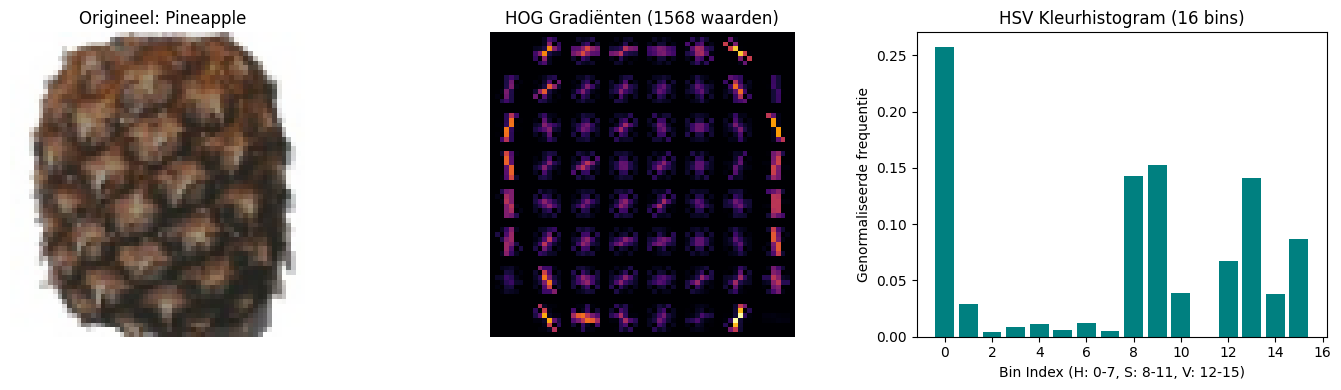

Dimensie samengestelde feature vector: 1584 (1568 HOG Gradiënten + 16 bins HSV kleurenhistogram)

Cell Size (pixels_per_cell): 
   Should be small enough to capture local shape details (such as edges and corners), but large enough to cover a meaningful gradient distribution.
   Standard choices are (8, 8) for detailed objects or (16, 16) for larger, coarser shapes.
Block Size (cells_per_block): 
   Defines the local region over which contrast normalization is applied to reduce the effect of illumination changes. 
   Standard practice uses (2, 2) cells per block, meaning each block slides across the grid with an overlap of 1 cel


In [5]:
# Laad een voorbeeldafbeelding van de eerste klasse
sample_class = geselecteerde_klassen[0]
sample_file = list((data_dir / sample_class).glob("*.*"))[0]
raw_img = imread(sample_file)

# 1. Beeldresolutie standaardiseren naar 64x64
img_64 = resize(raw_img, (64, 64), anti_aliasing=True)
if img_64.ndim == 3 and img_64.shape[-1] == 4:
    img_64 = img_64[:, :, :3]

# 2. Kleurfeature berekening (HSV Histogram)
img_hsv = rgb2hsv(img_64)
hist_h, _ = np.histogram(img_hsv[:, :, 0], bins=8, range=(0, 1))
hist_s, _ = np.histogram(img_hsv[:, :, 1], bins=4, range=(0, 1))
hist_v, _ = np.histogram(img_hsv[:, :, 2], bins=4, range=(0, 1))
color_vector = np.concatenate([hist_h, hist_s, hist_v]).astype(np.float32)
color_vector /= (np.sum(color_vector) + 1e-6)

# 3. Vormfeature berekening (HOG op grijswaarden)
img_gray = rgb2gray(img_64)
hog_vector, hog_vis = hog(
    img_gray,
    orientations=8,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    visualize=True,
    block_norm='L2-Hys'
)

# Plot inspectie
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(img_64)
axes[0].set_title(f"Origineel: {sample_class}")
axes[0].axis("off")

axes[1].imshow(hog_vis, cmap="inferno")
axes[1].set_title(f"HOG Gradiënten ({len(hog_vector)} waarden)")
axes[1].axis("off")

axes[2].bar(range(len(color_vector)), color_vector, color="teal")
axes[2].set_title(f"HSV Kleurhistogram ({len(color_vector)} bins)")
axes[2].set_xlabel("Bin Index (H: 0-7, S: 8-11, V: 12-15)")
axes[2].set_ylabel("Genormaliseerde frequentie")

plt.tight_layout()
plt.show()

print(f"Dimensie samengestelde feature vector: {len(color_vector) + len(hog_vector)} (1568 HOG Gradiënten + 16 bins HSV kleurenhistogram)")
print(f"")
print(f"Cell Size (pixels_per_cell): ")
print(f"   Should be small enough to capture local shape details (such as edges and corners), but large enough to cover a meaningful gradient distribution.") 
print(f"   Standard choices are (8, 8) for detailed objects or (16, 16) for larger, coarser shapes.")
print(f"Block Size (cells_per_block): ")
print(f"   Defines the local region over which contrast normalization is applied to reduce the effect of illumination changes. ")
print(f"   Standard practice uses (2, 2) cells per block, meaning each block slides across the grid with an overlap of 1 cel")

## **Stap 4:** Dataset Extractie
We verpakken de extractie in één functie en verwerken een representatieve steekproef per klasse (MAX_SAMPLES_PER_CLASS) zodat de data vlot in het werkgeheugen past.

In [6]:
def extract_scale_features(image_rgb, target_size=(64, 64)):
    """Zet een invoerafbeelding om naar een gecombineerde HSV+HOG featurevector."""
    img_res = resize(image_rgb, target_size, anti_aliasing=True)
    if img_res.ndim == 3 and img_res.shape[-1] >= 3:
        img_res = img_res[:, :, :3]
    
    # 1. HSV Histogram
    img_hsv = rgb2hsv(img_res)
    h_hist, _ = np.histogram(img_hsv[:, :, 0], bins=8, range=(0, 1))
    s_hist, _ = np.histogram(img_hsv[:, :, 1], bins=4, range=(0, 1))
    v_hist, _ = np.histogram(img_hsv[:, :, 2], bins=4, range=(0, 1))
    color_feats = np.concatenate([h_hist, s_hist, v_hist]).astype(np.float32)
    color_feats /= (np.sum(color_feats) + 1e-6)

    # 2. HOG Features
    img_gray = rgb2gray(img_res)
    hog_feats = hog(
        img_gray,
        orientations=8,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm='L2-Hys'
    )
    
    return np.concatenate([color_feats, hog_feats])

# Extractie over de geselecteerde klassen
MAX_SAMPLES_PER_CLASS = 150  # 150 foto's * 10 klassen = 1500 samples (ideaal voor snelle iteratie)
X_list, y_list = [], []

print("Extractie van features gestart...")
for class_name in tqdm(geselecteerde_klassen, desc="Klassen verwerken"):
    folder = data_dir / class_name
    img_paths = list(folder.glob("*.jpg")) + list(folder.glob("*.png"))
    img_paths = img_paths[:MAX_SAMPLES_PER_CLASS]
    
    for p in img_paths:
        try:
            im = imread(p)
            if im is None:
                continue
            feats = extract_scale_features(im)
            X_list.append(feats)
            y_list.append(class_name)
        except Exception:
            continue

X = np.array(X_list)
y = np.array(y_list)

print(f"\nMatrix geconstrueerd:")
print(f"- Feature matrix (X): {X.shape[0]} exemplaren met {X.shape[1]} features")
print(f"- Labels (y):         {y.shape[0]} labels")

Extractie van features gestart...


Klassen verwerken: 100%|██████████| 6/6 [00:06<00:00,  1.10s/it]


Matrix geconstrueerd:
- Feature matrix (X): 900 exemplaren met 1584 features
- Labels (y):         900 labels


## **Stap 5:** Splitsen en Standaardisatie
We splitsen in een training set (75%) en test set (25%) met behoud van gelijke klasse-verhoudingen (stratify). Vervolgens schalen we de data met StandardScaler. Dit is strikt noodzakelijk voor gradient-based algoritmes zoals Logistic Regression.

In [7]:
# Converteer tekstlabels naar gehele getallen (vereist voor oa. XGBoost)
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Stratified Train/Test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.25,
    random_state=42,
    stratify=y_encoded
)

# Features schalen op basis van enkel trainingsstatistieken
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set: {X_train_scaled.shape[0]} samples (van de {X.shape[0]} samples)")
print(f"Test set:     {X_test_scaled.shape[0]} samples (van de {X.shape[0]} samples)")

Training set: 675 samples (van de 900 samples)
Test set:     225 samples (van de 900 samples)


## **Stap 7:** Pipeline voor de modellen
We trainen de 6 vereiste algoritmes en evalueren:

Train & Test Accuracy (Top-1: is de eerste gok juist?)

Top-3 Accuracy (Zit het juiste product tussen de eerste 3 touchscreen-knoppen?)

Trainingstijd (s)

Gemiddelde Latency per scan (ms) (cruciaal voor realtime respons op de weegschaal)

In [8]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, C=0.5, solver='lbfgs', random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=12, min_samples_split=4, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=16, n_jobs=-1, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=60, learning_rate=0.3, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=80, learning_rate=0.1, max_depth=3, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=4, n_jobs=-1, eval_metric='mlogloss', random_state=42)
}

benchmark_results = []
test_probabilities = {}

for name, model in models.items():
    print(f"Training gestart voor: {name}...")
    
    # 1. Trainingstijd meten
    t0 = time.time()
    model.fit(X_train_scaled, y_train)
    t_train = time.time() - t0
    
    # 2. Predictie waarschijnlijkheden & inferentiesnelheid meten
    t_infer_start = time.time()
    probs = model.predict_proba(X_test_scaled)
    t_infer_total = time.time() - t_infer_start
    latency_ms = (t_infer_total / len(X_test_scaled)) * 1000.0
    
    test_probabilities[name] = probs
    
    # 3. Metrieken berekenen
    preds_test = np.argmax(probs, axis=1)
    preds_train = model.predict(X_train_scaled)
    
    top1_train = accuracy_score(y_train, preds_train) * 100.0
    top1_test = accuracy_score(y_test, preds_test) * 100.0
    top3_test = top_k_accuracy_score(y_test, probs, k=min(3, len(geselecteerde_klassen))) * 100.0
    
    benchmark_results.append({
        "Model": name,
        "Train Acc (%)": round(top1_train, 2),
        "Top-1 Acc (%)": round(top1_test, 2),
        "Top-3 Acc (%)": round(top3_test, 2),
        "Training (s)": round(t_train, 2),
        "Latency (ms/item)": round(latency_ms, 3)
    })

df_results = pd.DataFrame(benchmark_results).sort_values(by="Top-1 Acc (%)", ascending=False)
display(df_results)

Training gestart voor: Logistic Regression...
Training gestart voor: Decision Tree...
Training gestart voor: Random Forest...
Training gestart voor: AdaBoost...
Training gestart voor: Gradient Boosting...
Training gestart voor: XGBoost...


,Model,Train Acc (%),Top-1 Acc (%),Top-3 Acc (%),Training (s),Latency (ms/item)
0,Logistic Regression,100.00,100.00,100.0,0.06,0.006
1,Decision Tree,100.00,100.00,100.0,0.43,0.006
2,Random Forest,100.00,100.00,100.0,0.33,0.193
4,Gradient Boosting,100.00,100.00,100.0,119.76,0.015
5,XGBoost,100.00,100.00,100.0,8.02,0.023
3,AdaBoost,66.52,66.67,100.0,9.26,0.306


## **Stap 8:** Vergelijkende Grafieken
We zetten de resultaten om in twee overzichtelijke grafieken: modelkwaliteit (Top-1 vs Top-3) en productierandvoorwaarden (snelheid).

C:\Users\chayb\AppData\Local\Temp\ipykernel_10536\3872780712.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_results, x="Model", y="Latency (ms/item)", palette="magma", ax=axes[1])


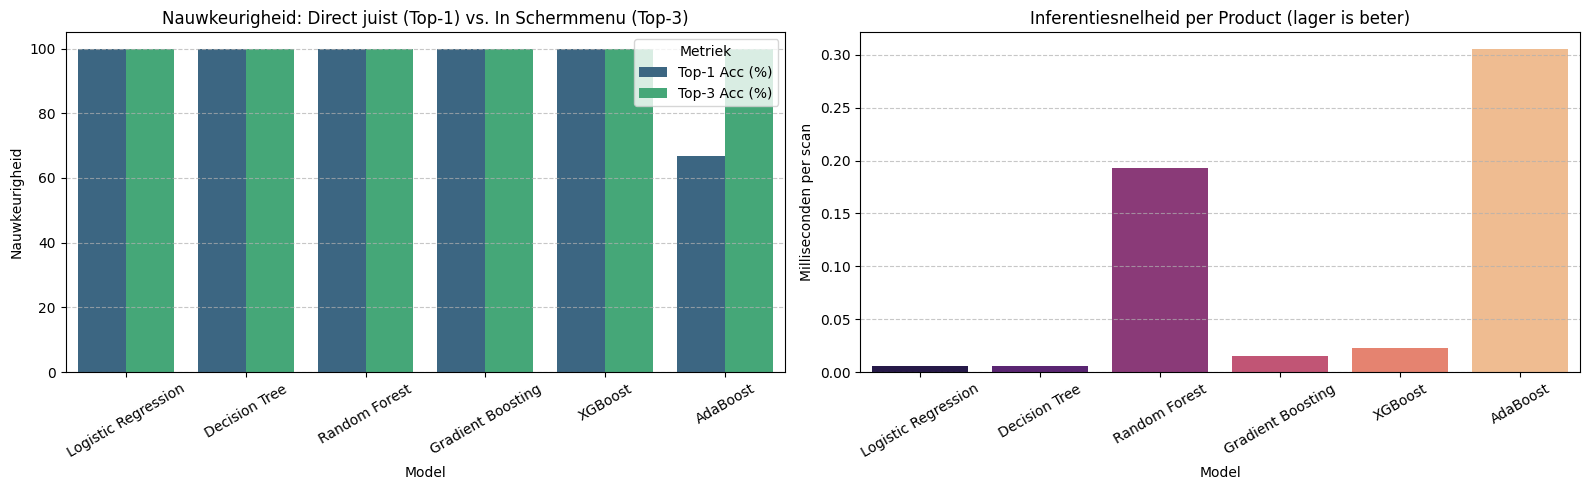

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Top-1 vs Top-3
df_plot = df_results.melt(
    id_vars=["Model"], 
    value_vars=["Top-1 Acc (%)", "Top-3 Acc (%)"], 
    var_name="Metriek", 
    value_name="Nauwkeurigheid"
)
sns.barplot(data=df_plot, x="Model", y="Nauwkeurigheid", hue="Metriek", palette="viridis", ax=axes[0])
axes[0].set_title("Nauwkeurigheid: Direct juist (Top-1) vs. In Schermmenu (Top-3)")
axes[0].set_ylim(0, 105)
axes[0].tick_params(axis='x', rotation=30)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Plot 2: Inferentie Latency
sns.barplot(data=df_results, x="Model", y="Latency (ms/item)", palette="magma", ax=axes[1])
axes[1].set_title("Inferentiesnelheid per Product (lager is beter)")
axes[1].tick_params(axis='x', rotation=30)
axes[1].set_ylabel("Milliseconden per scan")
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

## **Stap 9:** Foutenanalyse met de confusion matrix
We bekijken de confusion matrix van het best presterende model om te achterhalen welke producten met elkaar worden verward.

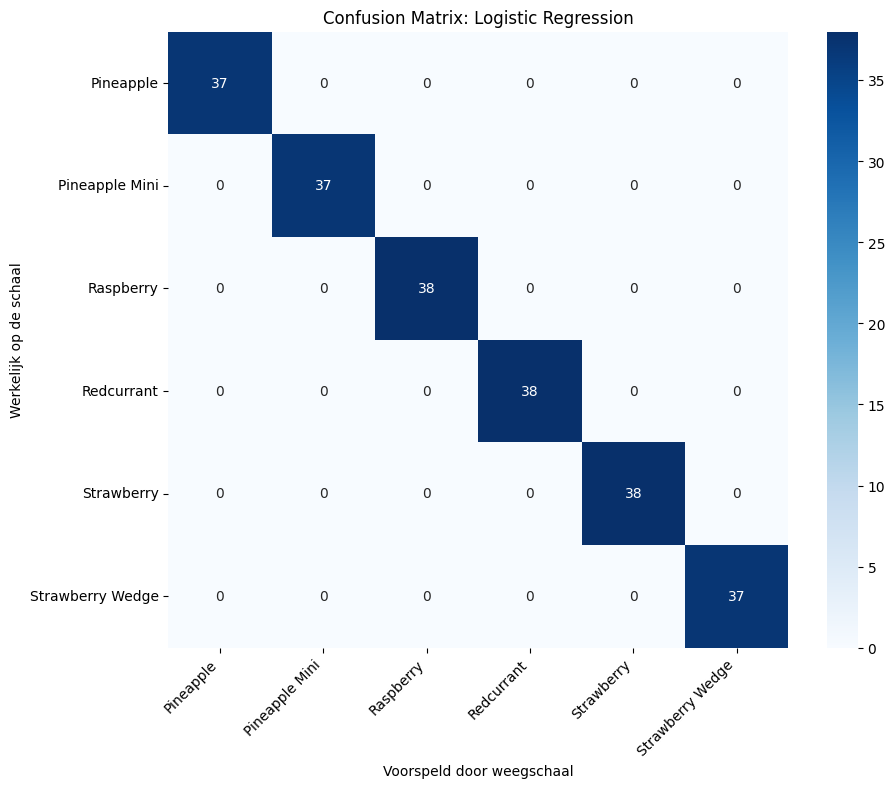


Gedetailleerd Classification Report (Logistic Regression):

                  precision    recall  f1-score   support

       Pineapple       1.00      1.00      1.00        37
  Pineapple Mini       1.00      1.00      1.00        37
       Raspberry       1.00      1.00      1.00        38
      Redcurrant       1.00      1.00      1.00        38
      Strawberry       1.00      1.00      1.00        38
Strawberry Wedge       1.00      1.00      1.00        37

        accuracy                           1.00       225
       macro avg       1.00      1.00      1.00       225
    weighted avg       1.00      1.00      1.00       225



In [10]:
best_model_name = df_results.iloc[0]["Model"]
y_pred_best = np.argmax(test_probabilities[best_model_name], axis=1)

cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=le.classes_, 
    yticklabels=le.classes_
)
plt.title(f"Confusion Matrix: {best_model_name}")
plt.xlabel("Voorspeld door weegschaal")
plt.ylabel("Werkelijk op de schaal")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.show()

print(f"\nGedetailleerd Classification Report ({best_model_name}):\n")
print(classification_report(y_test, y_pred_best, target_names=le.classes_))

## **Stap 10:** Interactieve Simulatie van het Weegschaalscherm
Deze functie simuleert wat de klant effectief te zien krijgt op de touchscreen display wanneer een willekeurig stuk fruit op de schaal wordt gelegd.

In [11]:
def simuleer_weegschaal_display(sample_index, gekozen_model="Random Forest"):
    probs = test_probabilities[gekozen_model][sample_index]
    top3_idx = np.argsort(probs)[-3:][::-1]
    
    werkelijk_label = le.inverse_transform([y_test[sample_index]])[0]
    
    print("+" + "-"*48 + "+")
    print(f"|  WEEGSCHAAL INTERFACE (Model: {gekozen_model:<18}) |")
    print("+" + "-"*48 + "+")
    print(f"  Gedetecteerd item op plaat: [ {werkelijk_label.upper()} ]")
    print("  Keuzemenu op scherm:")
    
    for rang, idx in enumerate(top3_idx, 1):
        naam = le.inverse_transform([idx])[0]
        kans = probs[idx] * 100
        match_icoon = "✔ JUIST" if naam == werkelijk_label else " "
        print(f"   [{rang}] {naam:<18} (Kans: {kans:5.1f}%) {match_icoon}")
    print("+" + "-"*48 + "+\n")

# Test de weegschaal op drie willekeurige items uit de testset
for idx in [5, 15, 25]:
    simuleer_weegschaal_display(sample_index=idx, gekozen_model=best_model_name)

+------------------------------------------------+
|  WEEGSCHAAL INTERFACE (Model: Logistic Regression) |
+------------------------------------------------+
  Gedetecteerd item op plaat: [ PINEAPPLE MINI ]
  Keuzemenu op scherm:
   [1] Pineapple Mini     (Kans: 100.0%) ✔ JUIST
   [2] Raspberry          (Kans:   0.0%)  
   [3] Pineapple          (Kans:   0.0%)  
+------------------------------------------------+

+------------------------------------------------+
|  WEEGSCHAAL INTERFACE (Model: Logistic Regression) |
+------------------------------------------------+
  Gedetecteerd item op plaat: [ STRAWBERRY ]
  Keuzemenu op scherm:
   [1] Strawberry         (Kans: 100.0%) ✔ JUIST
   [2] Pineapple          (Kans:   0.0%)  
   [3] Raspberry          (Kans:   0.0%)  
+------------------------------------------------+

+------------------------------------------------+
|  WEEGSCHAAL INTERFACE (Model: Logistic Regression) |
+------------------------------------------------+
  Gedetecteerd 

## **Extra:** HOG

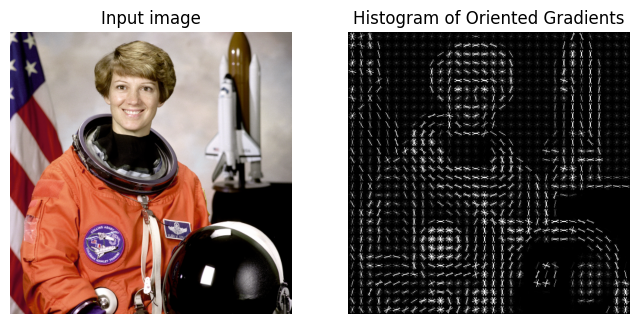

Meer informatie: 
 - https://scikit-image.org/docs/stable/auto_examples/features_detection/plot_hog.html
 - https://www.geeksforgeeks.org/machine-learning/hog-feature-visualization-in-python-using-skimage/


In [12]:

import matplotlib.pyplot as plt

from skimage.feature import hog
from skimage import data, exposure


image = data.astronaut()

fd, hog_image = hog(
    image,
    orientations=8,
    pixels_per_cell=(16, 16),
    cells_per_block=(1, 1),
    visualize=True,
    channel_axis=-1,
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4), sharex=True, sharey=True)

ax1.axis('off')
ax1.imshow(image, cmap=plt.cm.gray)
ax1.set_title('Input image')

# Rescale histogram for better display
hog_image_rescaled = exposure.rescale_intensity(hog_image, in_range=(0, 10))

ax2.axis('off')
ax2.imshow(hog_image_rescaled, cmap=plt.cm.gray)
ax2.set_title('Histogram of Oriented Gradients')
plt.show()
print("Meer informatie: ")
print(" - https://scikit-image.org/docs/stable/auto_examples/features_detection/plot_hog.html")
print(" - https://www.geeksforgeeks.org/machine-learning/hog-feature-visualization-in-python-using-skimage/")

In [13]:
hog_image

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(512, 512))